# Qui utilise mon appli ? Identification des utilisateurs de Copilote

Chaque ligne des données est une session du logiciel Copilote : le navigateur utilisé, puis la liste des actions réalisées. Il faut retrouver l'utilisateur (parmi 247) qui a fait la session : c'est une classification supervisée à 247 classes.

Plan :
1. Chargement des données
2. Format d'une action
3. Exploration
4. Représentation des sessions
5. Comparaison des modèles
6. Amélioration du score
7. Analyse des erreurs et interprétation
8. Fichiers de soumission

In [1]:
import csv
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, make_scorer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

GRIS, BLEU = "#b4b2a9", "#2a78d6"  # gris pour les données, bleu pour ce qu'on veut montrer
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "axes.axisbelow": True, "axes.titleweight": "bold"})
pourcent = PercentFormatter(1.0)  # affiche 0.95 comme 95 %

## 1. Chargement des données

Format d'une ligne du train : `utilisateur, navigateur, action, action, ...` (le test n'a pas la colonne utilisateur).

Les sessions n'ont pas la même longueur : la plus longue compte près de 12 000 actions (plus de 14 000 éléments avec les repères de temps). `pd.read_csv` créerait un tableau de 14 000 colonnes presque vides, dans lequel la colonne 57 n'aurait pas de sens commun d'une session à l'autre. On lit donc chaque ligne comme une liste.

In [2]:
def lire(chemin, avec_utilisateur):
    utilisateurs, navigateurs, sessions = [], [], []
    with open(chemin, encoding="utf-8") as f:
        for ligne in csv.reader(f):
            if avec_utilisateur:
                utilisateurs.append(ligne.pop(0))
            navigateurs.append(ligne[0])
            sessions.append(ligne[1:])
    return np.array(utilisateurs), navigateurs, sessions

y, nav, sessions = lire("data/train.csv", avec_utilisateur=True)
_, nav_test, sessions_test = lire("data/test.csv", avec_utilisateur=False)

print(len(sessions), "sessions d'entraînement,", len(set(y)), "utilisateurs,", len(sessions_test), "sessions de test")
print("Exemple :", y[0], nav[0], sessions[0][:5])

3279 sessions d'entraînement, 247 utilisateurs, 324 sessions de test
Exemple : nuh Firefox ["Création d'un écran(infologic.core.accueil.AccueilController)", "Affichage d'une dialogue", "Exécution d'un bouton", "Fermeture d'une dialogue", "Affichage d'une dialogue"]


## 2. Format d'une action

D'après la description des données, une action peut contenir plusieurs informations :

| Motif | Sens | Exemple |
|---|---|---|
| texte avant `(`, `<` ou `$` | type d'action | `Saisie dans un champ` |
| `(...)` | écran | `(infologic.crm.modules.CRM_ANNUAIRE.AnnuaireController)` |
| `<...>` | configuration d'écran | `<DEF_03/24>` |
| `$...$` | chaîne (catégorie de fiche) | `$GP$` |
| `1` à la fin | fiche en modification | `Saisie dans un champ1` |

Les jetons `t5`, `t10`, `t15`... ne sont pas des actions mais des repères de temps (en secondes).

La fonction `decouper` sépare ces informations avec des expressions régulières. Pour les écrans, on garde la fin du nom (`AnnuaireController`).

In [3]:
RE_TEMPS = re.compile(r"t\d+")

def decouper(action):
    modif = action.endswith("1")
    if modif:
        action = action[:-1]
    return {
        "type": re.split(r"[(<$]", action)[0].strip(),
        "ecrans": [e.split(".")[-1] for e in re.findall(r"\((.*?)\)", action)],  # on garde la fin du nom
        "configs": re.findall(r"<(.*?)>", action),
        "chaines": re.findall(r"\$(.*?)\$", action),
        "modif": modif,
    }

decouper("Saisie dans un champ(MAINT)<DEF_03/24>$GP$1")

{'type': 'Saisie dans un champ',
 'ecrans': ['MAINT'],
 'configs': ['DEF_03/24'],
 'chaines': ['GP'],
 'modif': True}

On calcule quelques statistiques par session : nombre d'actions, durée (plus grand repère `tXX`), nombre de types d'action et d'écrans distincts.

In [4]:
def statistiques(session):
    temps = [int(j[1:]) for j in session if RE_TEMPS.fullmatch(j)]
    actions = [decouper(j) for j in session if not RE_TEMPS.fullmatch(j)]
    return {
        "nb_actions": len(actions),
        "duree_s": max(temps, default=0),
        "nb_types": len({a["type"] for a in actions}),
        "nb_ecrans": len({e for a in actions for e in a["ecrans"]}),
    }

stats = pd.DataFrame([statistiques(s) for s in sessions])
stats["utilisateur"] = y
stats["navigateur"] = nav
stats_test = pd.DataFrame([statistiques(s) for s in sessions_test])
stats.describe().round(1)

,nb_actions,duree_s,nb_types,nb_ecrans
count,3279.0,3279.0,3279.0,3279.0
mean,692.4,751.5,17.0,10.7
std,1005.9,1006.3,4.3,5.8
min,0.0,5.0,0.0,0.0
25%,153.0,185.0,14.0,6.0
50%,340.0,395.0,17.0,9.0
75%,818.5,945.0,20.0,14.0
max,11977.0,11790.0,29.0,42.0


## 3. Exploration

### 3.1 Sessions par utilisateur

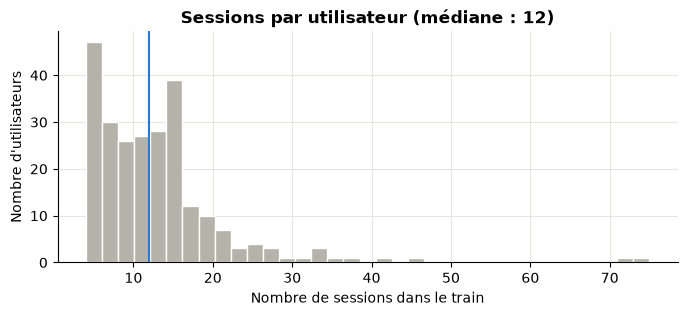

Minimum : 4 | maximum : 75
Si on répond toujours l'utilisateur le plus fréquent : 2.3% de bonnes réponses


In [5]:
sessions_par_util = stats.utilisateur.value_counts()

plt.figure(figsize=(8, 3))
plt.hist(sessions_par_util, bins=35, color=GRIS, edgecolor="white")
plt.axvline(sessions_par_util.median(), color=BLEU)
plt.title(f"Sessions par utilisateur (médiane : {sessions_par_util.median():.0f})")
plt.xlabel("Nombre de sessions dans le train")
plt.ylabel("Nombre d'utilisateurs")
plt.show()

print("Minimum :", sessions_par_util.min(), "| maximum :", sessions_par_util.max())
print(f"Si on répond toujours l'utilisateur le plus fréquent : {sessions_par_util.max() / len(y):.1%} de bonnes réponses")

- 12 sessions par utilisateur en médiane, 4 au minimum : il faut apprendre chaque utilisateur à partir de très peu d'exemples.
- Les classes sont déséquilibrées (de 4 à 75 sessions), mais aucun utilisateur ne domine : prédire toujours le plus fréquent donne 2,3 %, et le hasard 1/247 = 0,4 %. Ce sont les deux références pour juger les modèles.

### 3.2 Navigateur

In [6]:
print("Nombre de navigateurs différents par utilisateur :", stats.groupby("utilisateur").navigateur.nunique().value_counts().to_dict())
print("Nombre d'utilisateurs par navigateur :", stats.groupby("navigateur").utilisateur.nunique().to_dict())
print("Sessions de test par navigateur :", pd.Series(nav_test).value_counts().to_dict())

Nombre de navigateurs différents par utilisateur : {1: 247}
Nombre d'utilisateurs par navigateur : {'Firefox': 114, 'Google Chrome': 93, 'Microsoft Edge': 39, 'Opera': 1}
Sessions de test par navigateur : {'Firefox': 147, 'Google Chrome': 133, 'Microsoft Edge': 42, 'Opera': 2}


- Chaque utilisateur n'utilise qu'un seul navigateur. Une session Edge ne peut donc venir que d'un des 39 utilisateurs d'Edge (utilisé en partie 6.4).
- Opera n'a qu'un utilisateur : les 2 sessions de test sous Opera viennent très probablement de lui.
- La répartition des navigateurs est la même dans le train et le test.

### 3.3 Longueur des sessions et valeurs extrêmes

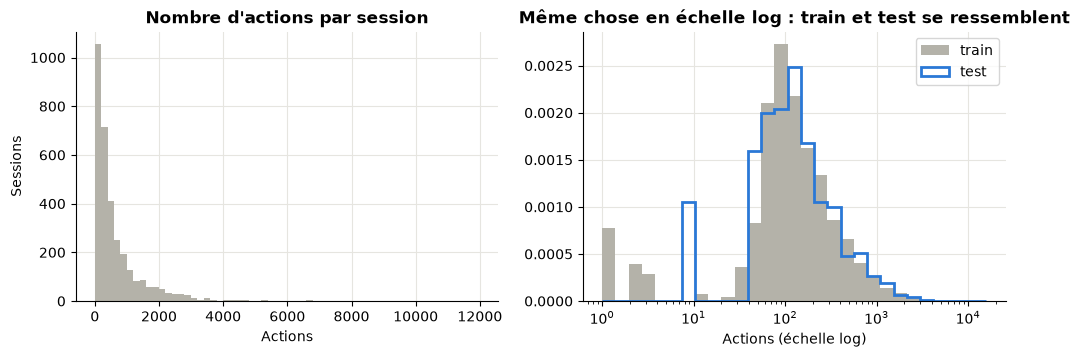

Sessions sans aucune action : 1
Seuil du 1 % de sessions les plus longues : 4697.199999999988 actions


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))

ax1.hist(stats.nb_actions, bins=60, color=GRIS)
ax1.set(title="Nombre d'actions par session", xlabel="Actions", ylabel="Sessions")

bins = np.logspace(0, 4.2, 30)
ax2.hist(stats.nb_actions + 1, bins=bins, color=GRIS, density=True, label="train")
ax2.hist(stats_test.nb_actions + 1, bins=bins, histtype="step", lw=2, color=BLEU, density=True, label="test")
ax2.set(xscale="log", title="Même chose en échelle log : train et test se ressemblent", xlabel="Actions (échelle log)")
ax2.legend()
plt.show()

print("Sessions sans aucune action :", (stats.nb_actions == 0).sum())
print("Seuil du 1 % de sessions les plus longues :", stats.nb_actions.quantile(0.99), "actions")

- La distribution est très asymétrique : la plupart des sessions ont quelques centaines d'actions, quelques-unes plus de 10 000.
- On garde toutes les sessions :
    - ce sont des sessions réelles, pas des erreurs de saisie ;
    - le test contient le même type de sessions (même distribution en échelle log) ;
    - certains utilisateurs n'ont que 4 sessions ;
    - la normalisation TF-IDF (partie 4) empêche une session longue de peser plus qu'une autre.
- Une session ne contient aucune action : seul son navigateur permet de la classer.

### 3.4 Types d'action

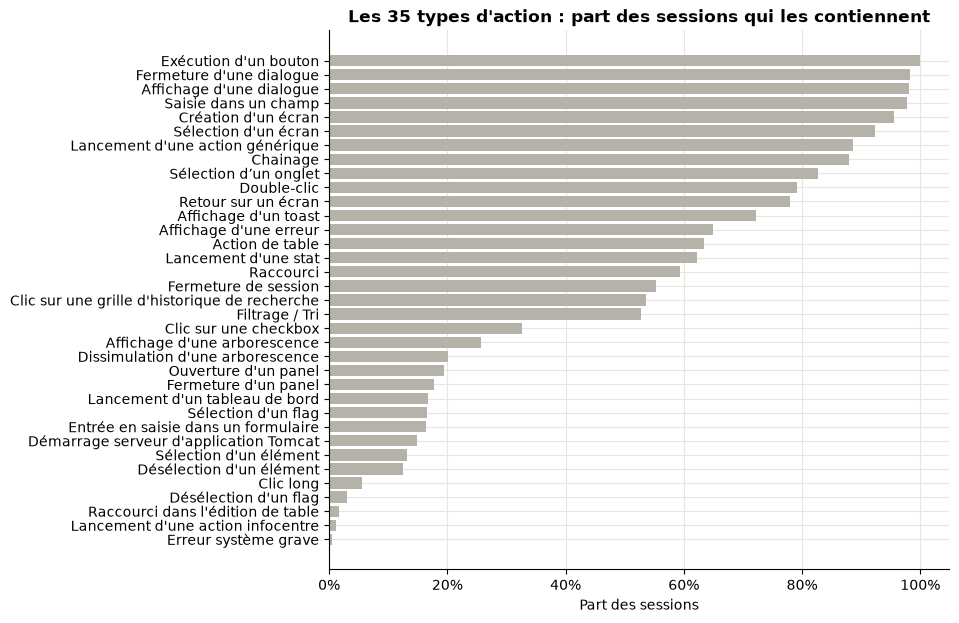

In [8]:
compte = Counter()
for s in sessions:
    compte.update({decouper(j)["type"] for j in s if not RE_TEMPS.fullmatch(j)})  # présence dans la session
presence = pd.Series(compte).sort_values() / len(sessions)

plt.figure(figsize=(8, 7))
plt.barh(presence.index, presence.values, color=GRIS)
plt.title(f"Les {len(presence)} types d'action : part des sessions qui les contiennent")
plt.xlabel("Part des sessions")
plt.gca().xaxis.set_major_formatter(pourcent)
plt.show()

- Il n'y a que 35 types d'action. Les plus courants (exécution d'un bouton, affichage d'une dialogue, saisie dans un champ) apparaissent dans presque toutes les sessions et ne distinguent personne.
- Les actions plus rares (tableau de bord, flags, panels) sont liées à certains métiers.
- Il faut donc réduire le poids des actions communes (rôle de l'IDF) et utiliser aussi les écrans, configurations et chaînes.

### 3.5 Similarité entre sessions d'un même utilisateur

Si les sessions d'une même personne ne se ressemblaient pas plus que celles de personnes différentes, aucun modèle ne pourrait fonctionner. On représente chaque session par la fréquence de ses types d'action et on compare les paires de sessions avec la similarité cosinus (1 = même profil, 0 = rien en commun).

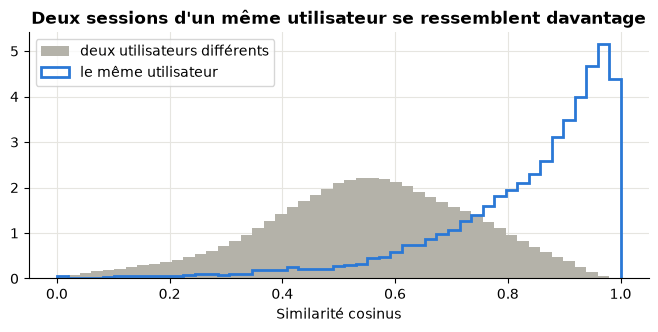

Similarité médiane : même utilisateur 0.88, utilisateurs différents 0.56


In [9]:
types_par_session = [" ".join(re.sub(r"\W+", "_", decouper(j)["type"]) for j in s if not RE_TEMPS.fullmatch(j)) for s in sessions]
X_types = TfidfVectorizer(token_pattern=r"\S+").fit_transform(types_par_session)
similarite = (X_types @ X_types.T).toarray()

meme_util = y[:, None] == y[None, :]
paires = np.triu(np.ones_like(similarite, dtype=bool), k=1)  # chaque paire une seule fois

plt.figure(figsize=(8, 3.2))
bins = np.linspace(0, 1, 50)
plt.hist(similarite[paires & ~meme_util], bins=bins, density=True, color=GRIS, label="deux utilisateurs différents")
plt.hist(similarite[paires & meme_util], bins=bins, density=True, histtype="step", lw=2, color=BLEU, label="le même utilisateur")
plt.title("Deux sessions d'un même utilisateur se ressemblent davantage")
plt.xlabel("Similarité cosinus")
plt.legend(loc="upper left")
plt.show()

print(f"Similarité médiane : même utilisateur {np.median(similarite[paires & meme_util]):.2f}, "
      f"utilisateurs différents {np.median(similarite[paires & ~meme_util]):.2f}")

- Similarité médiane de 0,88 pour deux sessions du même utilisateur, contre 0,56 pour deux utilisateurs différents : chaque utilisateur a une façon de travailler reconnaissable.
- Les deux distributions se chevauchent : les types d'action seuls ne suffiront pas, il faut ajouter l'ordre des actions et les écrans.

## 4. Représentation des sessions

Un modèle a besoin d'un vecteur de taille fixe par session. On traite chaque session comme un document dont les actions sont les mots, ce qui permet d'utiliser les méthodes de classification de textes.

Chaque action donne un ou plusieurs mots : son type, puis éventuellement son écran, sa configuration, sa chaîne et `MODIF`. Le navigateur est ajouté comme un mot en début de session.

In [10]:
def mot(texte):
    """Transforme un texte en un seul mot (sans espaces ni ponctuation)."""
    return re.sub(r"\W+", "_", texte).strip("_")

def session_en_texte(session, navigateur, details=True, avec_nav=True, avec_temps=False):
    mots = ["NAV_" + mot(navigateur)] if avec_nav else []
    for jeton in session:
        if RE_TEMPS.fullmatch(jeton):
            if avec_temps:
                mots.append("TEMPS")  # option testée en partie 6.5 : garder le rythme de la session
            continue
        a = decouper(jeton)
        mots.append(mot(a["type"]))
        if details:
            mots += ["ECRAN_" + mot(e) for e in a["ecrans"]]
            mots += ["CONF_" + mot(c) for c in a["configs"]]
            mots += ["CHAINE_" + mot(c) for c in a["chaines"]]
            if a["modif"]:
                mots.append("MODIF")
    return " ".join(mots)

textes = [session_en_texte(s, n) for s, n in zip(sessions, nav)]
textes_test = [session_en_texte(s, n) for s, n in zip(sessions_test, nav_test)]
print(textes[1][:400])

NAV_Google_Chrome Création_d_un_écran ECRAN_BlankController Création_d_un_écran ECRAN_InputFormNestedWindow Sélection_d_un_onglet ECRAN_InstanceForm CONF_TELEM_MINIMAL Exécution_d_un_bouton Sélection_d_un_onglet Exécution_d_un_bouton Chainage Sélection_d_un_onglet ECRAN_MAJ Sélection_d_un_écran ECRAN_InstanceForm Sélection_d_un_écran Exécution_d_un_bouton Chainage Saisie_dans_un_champ ECRAN_MAINT 


Les textes sont vectorisés avec TF-IDF :

- TF : un mot fréquent dans la session a plus de poids. Avec `sublinear_tf=True`, on prend le logarithme du nombre d'occurrences, pour que 500 clics ne pèsent pas 100 fois plus que 5.
- IDF : un mot présent dans presque toutes les sessions (`Exécution_d_un_bouton`) reçoit un poids faible.
- Chaque vecteur est normalisé (norme 1), ce qui rend comparables une session de 20 actions et une de 5 000. C'est ce qui permet de garder les sessions longues.

Avec `ngram_range=(1, 2)`, on ajoute les bigrammes (paires de mots consécutifs) pour garder une partie de l'ordre. Comme une action peut produire plusieurs mots, un bigramme est soit une transition entre deux actions (`Raccourci Exécution_d_un_bouton`), soit une action associée à son écran (`Raccourci ECRAN_SaisiEcritForm`).

In [11]:
def tfidf(n_max=2):
    """TF-IDF sur les mots séparés par des espaces, avec les n-grammes de 1 à n_max mots."""
    return TfidfVectorizer(token_pattern=r"\S+", lowercase=False, sublinear_tf=True,
                           ngram_range=(1, n_max), min_df=2)

print("Taille du vocabulaire (mots et bigrammes présents dans au moins 2 sessions) :", len(tfidf().fit(textes).vocabulary_))

Taille du vocabulaire (mots et bigrammes présents dans au moins 2 sessions) : 9002


## 5. Comparaison des modèles

### Protocole d'évaluation

Validation croisée stratifiée à 4 plis :
- on entraîne sur 3 parts et on évalue sur la 4e, quatre fois ;
- stratifiée : chaque part contient à peu près la même proportion de chaque utilisateur ;
- 4 plis car l'utilisateur le plus rare a 4 sessions : chaque part de test contient une de ses sessions et chaque entraînement en garde 3. Avec 5 plis, ces utilisateurs manqueraient dans une des parts de test.

Le TF-IDF est dans un pipeline avec le modèle : le vocabulaire et l'IDF sont recalculés à chaque pli sur les seules données d'entraînement, ce qui évite une fuite de données.

Métriques :
- accuracy : part des sessions attribuées au bon utilisateur (métrique du challenge) ;
- F1 macro : F1-score de chaque utilisateur, moyenné sur les 247 utilisateurs. Chaque utilisateur compte autant, quel que soit son nombre de sessions ; un F1 macro plus bas que l'accuracy indique que les utilisateurs rares sont moins bien reconnus.

On relève aussi le temps d'entraînement moyen par pli.

In [12]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)
f1_macro = make_scorer(f1_score, average="macro", zero_division=0)

def evaluer(modele, X, cv=cv):
    """Accuracy (moyenne et écart-type sur les plis), F1 macro et temps d'entraînement moyen."""
    res = cross_validate(modele, X, y, cv=cv, scoring={"accuracy": "accuracy", "f1": f1_macro}, n_jobs=4)
    return {"accuracy": res["test_accuracy"].mean(), "ecart": res["test_accuracy"].std(),
            "f1": res["test_f1"].mean(), "temps": res["fit_time"].mean()}

def afficher(nom, r):
    print(f"{nom:42s} accuracy = {r['accuracy']:.1%} (± {r['ecart']:.1%})   F1 macro = {r['f1']:.1%}   entraînement : {r['temps']:.1f} s")

Modèles comparés :

1. Classe majoritaire : prédit toujours l'utilisateur le plus fréquent (référence minimale).
2. Forêt aléatoire sur un tableau de 43 variables : statistiques de la session (partie 2), navigateur et part de chaque type d'action.
3. Plus proche voisin : utilisateur de la session d'entraînement la plus similaire (cosinus).
4. Régression logistique et 5. SVM linéaire sur les vecteurs TF-IDF.

La régression logistique et le SVM sont d'abord testés avec une valeur de C fixée à la main ; les deux sont réglés en partie 6.

In [13]:
# Tableau de variables pour la forêt aléatoire
textes_types = [session_en_texte(s, n, details=False, avec_nav=False) for s, n in zip(sessions, nav)]
comptes = CountVectorizer(token_pattern=r"\S+", lowercase=False).fit_transform(textes_types).toarray()
parts_types = comptes / np.maximum(comptes.sum(axis=1, keepdims=True), 1)
X_tableau = np.hstack([stats[["nb_actions", "duree_s", "nb_types", "nb_ecrans"]].values,
                       pd.get_dummies(stats.navigateur).values, parts_types])

modeles = {
    "Classe majoritaire": (DummyClassifier(), textes),
    "Forêt aléatoire (tableau de variables)": (RandomForestClassifier(n_estimators=300, random_state=0), X_tableau),
    "Plus proche voisin (TF-IDF)": (make_pipeline(tfidf(), KNeighborsClassifier(n_neighbors=1, metric="cosine")), textes),
    "Régression logistique (TF-IDF)": (make_pipeline(tfidf(), LogisticRegression(C=10, max_iter=1000)), textes),
    "SVM linéaire (TF-IDF)": (make_pipeline(tfidf(), LinearSVC(C=0.5)), textes),
}

resultats = {}
for nom, (modele, X) in modeles.items():
    resultats[nom] = evaluer(modele, X)
    afficher(nom, resultats[nom])

Classe majoritaire                         accuracy = 2.3% (± 0.1%)   F1 macro = 0.0%   entraînement : 0.0 s


Forêt aléatoire (tableau de variables)     accuracy = 85.1% (± 2.0%)   F1 macro = 81.9%   entraînement : 11.2 s


Plus proche voisin (TF-IDF)                accuracy = 89.4% (± 1.2%)   F1 macro = 87.6%   entraînement : 2.2 s


Régression logistique (TF-IDF)             accuracy = 93.3% (± 0.6%)   F1 macro = 90.5%   entraînement : 24.5 s


SVM linéaire (TF-IDF)                      accuracy = 94.7% (± 0.8%)   F1 macro = 92.7%   entraînement : 4.4 s


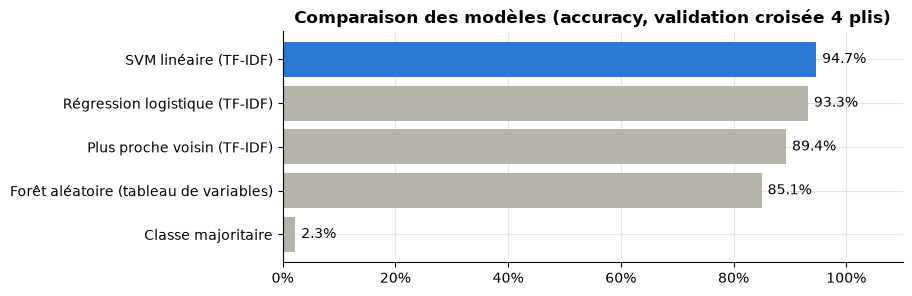

In [14]:
acc = pd.Series({nom: r["accuracy"] for nom, r in resultats.items()}).sort_values()
plt.figure(figsize=(8, 3))
plt.barh(acc.index, acc.values, color=[BLEU if v == acc.max() else GRIS for v in acc])
for i, v in enumerate(acc.values):
    plt.text(v + 0.01, i, f"{v:.1%}", va="center")
plt.xlim(0, 1.1)
plt.gca().xaxis.set_major_formatter(pourcent)
plt.title("Comparaison des modèles (accuracy, validation croisée 4 plis)")
plt.show()

- Tous les modèles dépassent largement la référence de 2,3 %.
- La forêt aléatoire atteint 85 %, mais son tableau de variables ne contient ni les écrans ni les chaînes : son retard vient en partie des données qu'elle reçoit.
- Le plus proche voisin (89 %) s'appuie sur une seule session voisine, ce qui le rend sensible au bruit.
- Les modèles linéaires sur TF-IDF sont les meilleurs :
    - environ 9 000 variables pour une douzaine de sessions par utilisateur : les classes sont presque toujours séparables linéairement, et un modèle plus complexe surapprendrait ;
    - les vecteurs TF-IDF sont creux, ce que les modèles linéaires traitent efficacement ;
    - le SVM maximise la marge entre chaque utilisateur et les autres (247 classifieurs « un contre tous »), ce qui limite le surapprentissage avec peu d'exemples.
- Le F1 macro est plus bas que l'accuracy pour tous les modèles ; l'écart est le plus grand pour la régression logistique (93,3 % contre 90,5 %).
- Le SVM s'entraîne environ 5 fois plus vite que la régression logistique.
- Les deux modèles linéaires n'étant pas encore réglés, leur comparaison est reprise en partie 6.3.

## 6. Amélioration du score

### 6.1 Apport de chaque information (ablation)

Avec le SVM, on ajoute les informations une par une pour mesurer l'apport de chacune.

In [15]:
etapes = {
    "types d'action seuls": dict(details=False, avec_nav=False, n_max=1),
    "+ bigrammes (ordre)": dict(details=False, avec_nav=False, n_max=2),
    "+ écrans, configs, chaînes": dict(details=True, avec_nav=False, n_max=2),
    "+ navigateur": dict(details=True, avec_nav=True, n_max=2),
}

def score_variante(details, avec_nav, n_max):
    X = [session_en_texte(s, n, details, avec_nav) for s, n in zip(sessions, nav)]
    return evaluer(make_pipeline(tfidf(n_max), LinearSVC(C=0.5)), X)["accuracy"]

ablation = {}
for nom, options in etapes.items():
    ablation[nom] = score_variante(**options)
    print(f"{nom:30s} {ablation[nom]:.1%}")

types d'action seuls           59.4%


+ bigrammes (ordre)            84.7%


+ écrans, configs, chaînes     94.1%


+ navigateur                   94.7%


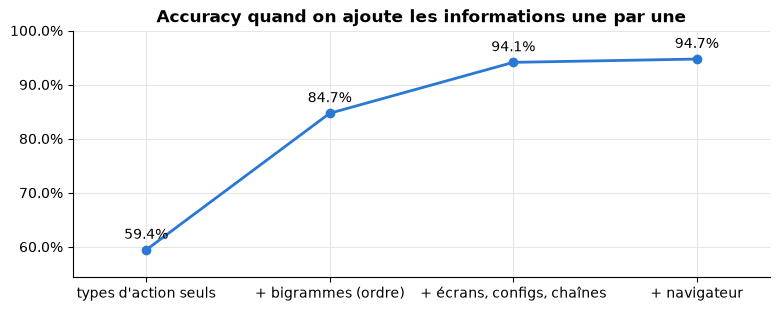

In [16]:
valeurs = list(ablation.values())
plt.figure(figsize=(9, 3.2))
plt.plot(list(ablation), valeurs, marker="o", color=BLEU, lw=2)
for i, v in enumerate(valeurs):
    plt.annotate(f"{v:.1%}", (i, v), xytext=(0, 8), textcoords="offset points", ha="center")
plt.ylim(min(valeurs) - 0.05, 1)
plt.xlim(-0.4, len(valeurs) - 0.6)
plt.gca().yaxis.set_major_formatter(pourcent)
plt.title("Accuracy quand on ajoute les informations une par une")
plt.show()

Le gain mesuré pour une information dépend de l'ordre d'ajout. Pour le vérifier, on ajoute les écrans, configurations et chaînes sans les bigrammes :

In [17]:
ecrans_sans_bigrammes = score_variante(details=True, avec_nav=False, n_max=1)
pd.DataFrame({"sans bigrammes": [ablation["types d'action seuls"], ecrans_sans_bigrammes],
              "avec bigrammes": [ablation["+ bigrammes (ordre)"], ablation["+ écrans, configs, chaînes"]]},
             index=["types d'action seuls", "+ écrans, configs, chaînes"]).map(lambda v: f"{v:.1%}")

,sans bigrammes,avec bigrammes
types d'action seuls,59.4%,84.7%
"+ écrans, configs, chaînes",85.3%,94.1%


- Les types d'action seuls donnent 59 % : 35 types ne suffisent pas pour 247 utilisateurs (cf. chevauchement en 3.5).
- Les bigrammes seuls et les écrans seuls donnent chacun environ 85 % : ils apportent autant l'un que l'autre, et les +25 points des bigrammes dans la première courbe viennent surtout de l'ordre d'ajout.
- Ensemble, ils gagnent encore 9 points : ils sont complémentaires. Les bigrammes décrivent la façon dont la personne enchaîne ses actions, les écrans ce sur quoi elle travaille.
- Le navigateur, ajouté comme un mot, n'apporte que 0,6 point (moins que l'écart-type entre plis). Il est utilisé autrement en partie 6.4.

### 6.2 Réglage de C pour le SVM

C règle le compromis entre sous-apprentissage (C petit) et surapprentissage (C grand).

Les écarts entre valeurs voisines de C sont du même ordre que la variation due au découpage. On répète donc la validation croisée 3 fois avec des découpages différents (`RepeatedStratifiedKFold`), soit 12 entraînements par valeur ; le SVM est assez rapide pour cela.

In [18]:
cv_repete = RepeatedStratifiedKFold(n_splits=4, n_repeats=3, random_state=0)

scores_C = {}
for C in [0.1, 0.3, 1, 3, 10, 30]:
    r = evaluer(make_pipeline(tfidf(), LinearSVC(C=C)), textes, cv=cv_repete)
    scores_C[C] = r["accuracy"]
    afficher(f"C = {C}", r)

meilleur_C = max(scores_C, key=scores_C.get)
print("Meilleur C :", meilleur_C)

C = 0.1                                    accuracy = 88.3% (± 1.0%)   F1 macro = 81.9%   entraînement : 5.9 s


C = 0.3                                    accuracy = 92.8% (± 0.8%)   F1 macro = 89.4%   entraînement : 5.7 s


C = 1                                      accuracy = 95.4% (± 0.7%)   F1 macro = 93.9%   entraînement : 5.5 s


C = 3                                      accuracy = 96.0% (± 0.7%)   F1 macro = 95.1%   entraînement : 6.0 s


C = 10                                     accuracy = 96.1% (± 0.6%)   F1 macro = 95.3%   entraînement : 6.2 s


C = 30                                     accuracy = 96.1% (± 0.6%)   F1 macro = 95.3%   entraînement : 6.4 s
Meilleur C : 10


- Avec C = 0,1 le modèle sous-apprend.
- Le score atteint un plateau à partir de C = 3 : entre 3, 10 et 30, les écarts (0,1 point au plus) sont bien inférieurs à l'écart-type. On garde C = 10.
- La grille va jusqu'à 30 pour vérifier que le meilleur C n'est pas sur le bord.
- Le réglage apporte environ 1,5 point par rapport à C = 0,5 (partie 5).

### 6.3 Réglage de la régression logistique

Pour que la comparaison soit équitable, on règle aussi C pour la régression logistique (3 valeurs seulement, car elle est plus lente).

In [19]:
for C in [10, 100, 1000]:
    afficher(f"Régression logistique, C = {C}", evaluer(make_pipeline(tfidf(), LogisticRegression(C=C, max_iter=1000)), textes))
afficher(f"SVM linéaire, C = {meilleur_C}", evaluer(make_pipeline(tfidf(), LinearSVC(C=meilleur_C)), textes))

Régression logistique, C = 10              accuracy = 93.3% (± 0.6%)   F1 macro = 90.5%   entraînement : 28.6 s


Régression logistique, C = 100             accuracy = 94.7% (± 0.4%)   F1 macro = 93.2%   entraînement : 29.0 s


Régression logistique, C = 1000            accuracy = 93.8% (± 1.3%)   F1 macro = 92.2%   entraînement : 19.3 s


SVM linéaire, C = 10                       accuracy = 96.2% (± 0.6%)   F1 macro = 95.4%   entraînement : 6.6 s


Réglée (C = 100), la régression logistique gagne environ 1,5 point mais reste derrière le SVM sur les mêmes plis, avec un F1 macro plus bas. On garde le SVM.

### 6.4 Le navigateur comme contrainte

Chaque utilisateur n'utilise qu'un navigateur (partie 3.2), mais dans le modèle le navigateur n'est qu'un mot parmi 9 000 : le SVM peut prédire un utilisateur de Chrome pour une session faite sous Firefox.

On applique donc la règle directement : pour chaque session, le SVM donne un score à chaque utilisateur (`decision_function`) ; on met −∞ pour les utilisateurs qui n'utilisent pas le navigateur de la session, puis on prend le meilleur score restant.

- Pas de fuite de données : chaque utilisateur a au moins 3 sessions dans l'entraînement de chaque pli, toutes avec le même navigateur, donc la règle serait identique si on la calculait sur l'entraînement seul.
- Risque : un utilisateur qui changerait de navigateur dans le test serait forcément mal classé. Aucun ne l'a fait sur les 3 279 sessions du train.

In [20]:
modele_final = make_pipeline(tfidf(), LinearSVC(C=meilleur_C))
classes = np.unique(y)          # même ordre que les colonnes de decision_function
nav_util = dict(zip(y, nav))    # le navigateur (unique) de chaque utilisateur

def masque_navigateur(navigateurs):
    """Tableau sessions x utilisateurs : True si l'utilisateur utilise le navigateur de la session."""
    return np.array([[nav_util[u] == n for u in classes] for n in navigateurs])

def predire_avec_navigateur(scores, navigateurs):
    """Meilleur utilisateur parmi ceux qui utilisent le navigateur de la session."""
    return classes[np.where(masque_navigateur(navigateurs), scores, -np.inf).argmax(axis=1)]

scores_cv = cross_val_predict(modele_final, textes, y, cv=cv, n_jobs=4, method="decision_function")
pred_svm = classes[scores_cv.argmax(axis=1)]
pred_final = predire_avec_navigateur(scores_cv, nav)

impossibles = np.array([nav_util[p] != n for p, n in zip(pred_svm, nav)])
print(f"SVM seul : {(pred_svm != y).sum()} erreurs, dont {impossibles.sum()} donnent un utilisateur qui n'utilise jamais ce navigateur\n")
for nom, p in [("SVM seul", pred_svm), ("SVM + contrainte du navigateur", pred_final)]:
    print(f"{nom:32s} accuracy = {accuracy_score(y, p):.1%}   F1 macro = {f1_score(y, p, average='macro'):.1%}")

SVM seul : 125 erreurs, dont 61 donnent un utilisateur qui n'utilise jamais ce navigateur

SVM seul                         accuracy = 96.2%   F1 macro = 95.8%
SVM + contrainte du navigateur   accuracy = 97.2%   F1 macro = 96.9%


Vérification sur deux autres découpages :

In [21]:
for graine in [1, 2]:
    cv_autre = StratifiedKFold(n_splits=4, shuffle=True, random_state=graine)
    s = cross_val_predict(modele_final, textes, y, cv=cv_autre, n_jobs=4, method="decision_function")
    print(f"Découpage {graine} : SVM seul {accuracy_score(y, classes[s.argmax(axis=1)]):.1%}, "
          f"avec la contrainte {accuracy_score(y, predire_avec_navigateur(s, nav)):.1%}")

Découpage 1 : SVM seul 96.5%, avec la contrainte 97.4%


Découpage 2 : SVM seul 95.9%, avec la contrainte 96.9%


- 61 des 125 erreurs du SVM désignaient un utilisateur qui n'utilise pas le navigateur de la session.
- La contrainte fait passer l'accuracy de 96,2 % à 97,2 %, et le gain se retrouve sur les autres découpages.

### 6.5 Pistes sans effet

Trois autres idées, comparées au SVM final sur les mêmes plis :
- trigrammes (suites de trois mots) ;
- plus de poids aux utilisateurs rares (`class_weight="balanced"`) ;
- repères de temps gardés comme mots (`TEMPS`), pour capter le rythme de la session.

In [22]:
textes_temps = [session_en_texte(s, n, avec_temps=True) for s, n in zip(sessions, nav)]
pistes = {
    "SVM final (référence)": (make_pipeline(tfidf(), LinearSVC(C=meilleur_C)), textes),
    "+ trigrammes": (make_pipeline(tfidf(3), LinearSVC(C=meilleur_C)), textes),
    "+ poids aux utilisateurs rares": (make_pipeline(tfidf(), LinearSVC(C=meilleur_C, class_weight="balanced")), textes),
    "+ repères de temps comme mots": (make_pipeline(tfidf(), LinearSVC(C=meilleur_C)), textes_temps),
}
for nom, (modele, X) in pistes.items():
    afficher(nom, evaluer(modele, X))

SVM final (référence)                      accuracy = 96.2% (± 0.6%)   F1 macro = 95.4%   entraînement : 9.2 s


+ trigrammes                               accuracy = 96.2% (± 0.6%)   F1 macro = 95.1%   entraînement : 25.5 s


+ poids aux utilisateurs rares             accuracy = 96.3% (± 0.6%)   F1 macro = 95.6%   entraînement : 8.9 s


+ repères de temps comme mots              accuracy = 96.4% (± 0.9%)   F1 macro = 95.7%   entraînement : 9.6 s


Les écarts avec la référence (0 à 0,2 point) sont inférieurs à l'écart-type entre plis (0,6 point) : aucune de ces pistes n'apporte de gain mesurable, et les trigrammes doublent le temps d'entraînement. On garde le modèle le plus simple.

## 7. Analyse des erreurs et interprétation

### 7.1 Sessions mal classées

On utilise les prédictions du modèle final (SVM + contrainte du navigateur) obtenues en 6.4 avec `cross_val_predict` : chaque session est prédite par le modèle entraîné sans elle.

Accuracy : 97.2% (93 erreurs sur 3279)


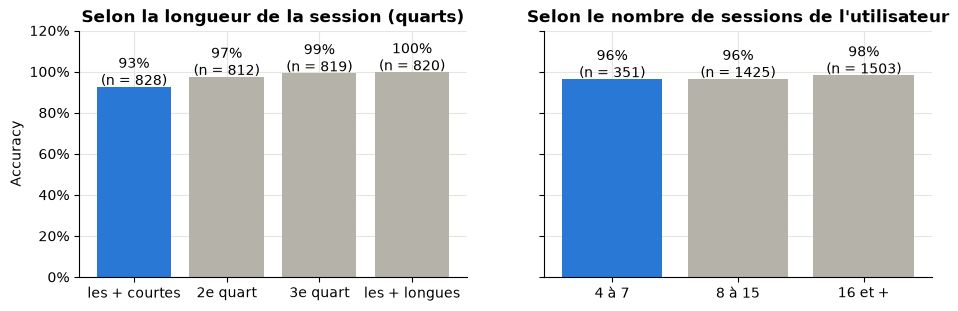

In [23]:
stats["correct"] = pred_final == y
print(f"Accuracy : {stats.correct.mean():.1%} ({(~stats.correct).sum()} erreurs sur {len(y)})")

stats["longueur"] = pd.qcut(stats.nb_actions, 4, labels=["les + courtes", "2e quart", "3e quart", "les + longues"])
stats["nb_sessions_util"] = pd.cut(stats.utilisateur.map(sessions_par_util), [0, 7, 15, 100], labels=["4 à 7", "8 à 15", "16 et +"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, colonne, titre in [(ax1, "longueur", "Selon la longueur de la session (quarts)"),
                           (ax2, "nb_sessions_util", "Selon le nombre de sessions de l'utilisateur")]:
    groupes = stats.groupby(colonne, observed=True).correct
    taux, effectifs = groupes.mean(), groupes.size()
    ax.bar(taux.index.astype(str), taux.values, color=[BLEU if v == taux.min() else GRIS for v in taux])
    for i, (v, n) in enumerate(zip(taux.values, effectifs.values)):
        ax.text(i, v + 0.01, f"{v:.0%}\n(n = {n})", ha="center")
    ax.set(title=titre, ylim=(0, 1.2))
    ax.yaxis.set_major_formatter(pourcent)
ax1.set_ylabel("Accuracy")
plt.show()

Rang du bon utilisateur parmi les choix du modèle, et paires d'utilisateurs les plus confondues :

In [24]:
scores_possibles = np.where(masque_navigateur(nav), scores_cv, -np.inf)
ordre = np.argsort(-scores_possibles, axis=1)    # utilisateurs, du plus probable au moins probable
bon = np.searchsorted(classes, y)                # position du vrai utilisateur dans classes
for k in [1, 3, 5]:
    print(f"Le bon utilisateur est dans les {k} premiers choix : {np.mean([bon[i] in ordre[i, :k] for i in range(len(y))]):.1%}")

erreurs = ~stats.correct.values
confusions = Counter(tuple(sorted(paire)) for paire in zip(y[erreurs], pred_final[erreurs]))
pd.DataFrame(confusions.most_common(6), columns=["paire d'utilisateurs", "erreurs"])

Le bon utilisateur est dans les 1 premiers choix : 97.2%
Le bon utilisateur est dans les 3 premiers choix : 99.1%
Le bon utilisateur est dans les 5 premiers choix : 99.4%


,paire d'utilisateurs,erreurs
0,"(skm, slq)",7
1,"(flj, skm)",6
2,"(oqa, xkr)",3
3,"(esu, lgd)",3
4,"(guh, hll)",3
5,"(jrc, snv)",2


- 93 erreurs sur 3 279 sessions (97,2 %). C a été choisi sur ces mêmes plis, donc ce score est légèrement optimiste ; le score Kaggle sert de mesure indépendante.
- Les sessions courtes sont les plus difficiles : peu d'actions, donc peu d'indices.
- Le nombre de sessions de l'utilisateur compte peu : environ 96 % pour 4 à 7 sessions comme pour 8 à 15, 98 % au-delà de 16. Sans la contrainte, l'écart paraissait plus grand, car une partie des erreurs sur les utilisateurs rares venait d'un mauvais navigateur.
- Le bon utilisateur est dans les 3 premiers choix pour 99,1 % des sessions.
- Les erreurs se concentrent sur quelques paires. `skm`, `slq` et `flj` sont parmi les utilisateurs les plus fréquents et utilisent les mêmes écrans comptables (partie 7.2).

### 7.2 Mots les plus influents

Un modèle linéaire apprend un poids par mot et par utilisateur. Les mots de plus fort poids d'un utilisateur forment sa signature.

In [25]:
modele_final.fit(textes, y)
vocabulaire = modele_final[0].get_feature_names_out()
poids = modele_final[-1].coef_

signatures = {}
for util in sessions_par_util.index[:4]:
    ligne = poids[list(modele_final[-1].classes_).index(util)]
    signatures[util] = vocabulaire[np.argsort(ligne)[::-1][:8]]
pd.DataFrame(signatures)

,skm,slq,cjr,flj
0,CONF_ADM_055,Affichage_d_une_dialogue ECRAN_HomeViewController,ECRAN_FormulaireForm,CONF_LERCNAT
1,Raccourci MODIF,NAV_Google_Chrome Exécution_d_un_bouton,Clic_sur_une_grille_d_historique_de_recherche ...,Sélection_d_un_onglet CONF_LERCNAT
2,Raccourci ECRAN_SaisiEcritForm,ECRAN_FicheFournisseurForm Sélection_d_un_onglet,ECRAN_EXPO,ECRAN_AvoirForm Raccourci
3,ECRAN_InputFormNestedWindow CONF_ADM_055,Saisie_dans_un_champ ECRAN_SaisiEcritForm,CONF_SuiviProdLog,ECRAN_InputFormNestedWindow CONF_LERCNAT
4,Clic_long MODIF,ECRAN_InterventionController Sélection_d_un_on...,ECRAN_BlankController CONF_SuiviProdLog,CONF_EV_BK
5,Sélection_d_un_onglet CONF_ADM_055,Exécution_d_un_bouton ECRAN_PdfViewerForm,ECRAN_CompteRenduForm Fermeture_de_session,CONF_LERCNAT Exécution_d_un_bouton
6,Raccourci,Lancement_d_une_stat Exécution_d_un_bouton,ECRAN_PlanifRepetitiveForm,CONF_LERCNAT Saisie_dans_un_champ
7,MODIF Clic_long,Lancement_d_une_stat Saisie_dans_un_champ,ECRAN_CompteRenduForm,CONF_LERCNAT MODIF


- Chaque colonne donne les 8 mots ou bigrammes de plus fort poids pour un utilisateur.
- On y trouve surtout des configurations (`CONF_...`) et des écrans (`ECRAN_...`), souvent associés à une action.
- `skm` et `slq` utilisent tous les deux l'écran de saisie d'écritures (`SaisiEcritForm`), ce qui explique qu'ils soient souvent confondus.
- Pour une vue d'ensemble sur les 247 utilisateurs, on regroupe les mots par famille.

In [26]:
def famille(terme):
    mots_du_terme = terme.split()
    if len(mots_du_terme) == 2:
        if any(m.split("_")[0] in ["ECRAN", "CONF", "CHAINE"] for m in mots_du_terme):
            return "bigramme avec écran, config ou chaîne"
        return "bigramme d'actions"
    for prefixe in ["ECRAN", "CONF", "CHAINE", "NAV"]:
        if terme.startswith(prefixe + "_"):
            return prefixe
    return "MODIF" if terme == "MODIF" else "type d'action"

familles = pd.Series([famille(t) for t in vocabulaire])
valeur_moyenne = np.asarray(modele_final[0].transform(textes).mean(axis=0)).ravel()  # valeur TF-IDF moyenne de chaque mot
contribution = pd.Series(np.abs(poids).sum(axis=0) * valeur_moyenne)                 # poids (sur les 247 utilisateurs) x valeur moyenne
importance = pd.DataFrame({"nombre de mots": familles.value_counts(),
                           "part de la contribution": contribution.groupby(familles).sum() / contribution.sum()})
importance.sort_values("part de la contribution", ascending=False).round(3)

,nombre de mots,part de la contribution
bigramme d'actions,984,0.440
"bigramme avec écran, config ou chaîne",7416,0.287
type d'action,35,0.143
ECRAN,296,0.067
CONF,198,0.027
CHAINE,68,0.022
MODIF,1,0.008
NAV,4,0.007


- La contribution d'un mot est son poids multiplié par sa valeur TF-IDF moyenne. Le poids seul serait trompeur : un mot présent partout (`NAV_Firefox`) a une valeur TF-IDF très faible et a besoin d'un grand poids pour compter.
- Les bigrammes d'actions (984 mots) ont la plus grande contribution : l'enchaînement des actions est ce qui distingue le plus les utilisateurs.
- Viennent ensuite les bigrammes contenant un écran, une configuration ou une chaîne, puis les écrans seuls, ce qui rejoint la complémentarité observée en 6.1.
- Le navigateur ne contribue presque pas, d'où l'intérêt de l'utiliser comme contrainte.
- Limite : les écrans sont identifiés par la fin de leur nom, et 14 noms courts regroupent deux écrans différents (par exemple `AvoirForm` pour les ventes et pour les achats). Garder le nom complet ne change pas le score, mais il faut en tenir compte pour lire une signature.

## 8. Fichiers de soumission

Le modèle final, entraîné sur toutes les sessions du train (partie 7.2), est appliqué au test. Deux fichiers sont enregistrés :
- `submission_v1_svm.csv` : SVM seul ;
- `submission_v2_svm_navigateur.csv` : SVM + contrainte du navigateur (version finale).

Scores obtenus sur Kaggle : 0,963 pour la v1 et 0,982 pour la v2. Sur 324 sessions, aucun nombre de bonnes réponses ne donne 0,982 (318 donnent 0,981, 319 donnent 0,985) : Kaggle ne note qu'une partie du test, environ 163 sessions. Les scores correspondent alors à 157 puis 160 bonnes réponses, soit 3 sessions corrigées par la contrainte, ce qui est cohérent avec les 4 prédictions modifiées.

In [27]:
scores_test = modele_final.decision_function(textes_test)
pred_test_svm = classes[scores_test.argmax(axis=1)]
pred_test = predire_avec_navigateur(scores_test, nav_test)
print("Prédictions modifiées par la contrainte du navigateur :", (pred_test != pred_test_svm).sum())
print("Sessions de test sous Opera attribuées à :", set(pred_test[np.array(nav_test) == "Opera"]))

def enregistrer(predictions, chemin):
    pd.DataFrame({"RowId": range(1, len(predictions) + 1), "prediction": predictions}).to_csv(chemin, index=False)
    print(len(predictions), "prédictions enregistrées dans", chemin)

enregistrer(pred_test_svm, "submission_v1_svm.csv")
enregistrer(pred_test, "submission_v2_svm_navigateur.csv")

Prédictions modifiées par la contrainte du navigateur : 4
Sessions de test sous Opera attribuées à : {np.str_('swe')}
324 prédictions enregistrées dans submission_v1_svm.csv
324 prédictions enregistrées dans submission_v2_svm_navigateur.csv


## Conclusion

| Étape | Choix | Raison |
|---|---|---|
| Lecture | une liste d'actions par session | longueurs très différentes |
| Valeurs extrêmes | conservées | sessions réelles, présentes aussi dans le test, neutralisées par la normalisation |
| Représentation | texte de mots (action, écran, configuration, chaîne, navigateur) + bigrammes, TF-IDF | garde le détail des écrans et une partie de l'ordre |
| Évaluation | validation croisée stratifiée à 4 plis, TF-IDF dans le pipeline ; accuracy et F1 macro | utilisateur le plus rare : 4 sessions ; pas de fuite de données |
| Modèle | SVM linéaire, C = 10 (validation croisée répétée) | meilleur score, y compris face à une régression logistique réglée |
| Post-traitement | restriction aux utilisateurs du navigateur de la session | un navigateur par utilisateur : +1 point |

| | Validation croisée (accuracy / F1 macro) | Kaggle |
|---|---|---|
| v1 : SVM seul | 96,2 % / 95,8 % | 0,963 |
| v2 : SVM + contrainte du navigateur | 97,2 % / 96,9 % | 0,982 |

Les utilisateurs se distinguent à la fois par l'enchaînement de leurs actions et par les écrans sur lesquels ils travaillent, deux informations complémentaires. La contrainte du navigateur, tirée de l'exploration, apporte le gain le plus net après le réglage de C. Les cas difficiles restent les sessions courtes et les utilisateurs qui travaillent sur les mêmes écrans.

Pistes : trigrammes, rééquilibrage des classes et repères de temps n'apportent rien (6.5). Comme le bon utilisateur est presque toujours dans les 3 premiers choix, un classifieur dédié aux paires d'utilisateurs souvent confondues serait la piste la plus prometteuse.